# METAMER-SAE — Notebook 09
## Integrated Model-Level Results and Scientific Synthesis

**Purpose.** Consolidate the validated findings from Notebook 07 (natural-image-trained TopK SAE feature analysis) and Notebook 08 (paired source / standard-metamer / adversarial-metamer evaluation) into one model-focused scientific account.

**Central project motivation.** *Which internal visual features differ when standard-trained and adversarially trained networks produce model metamers with different perceptual properties?* This notebook addresses the model-representation part of that question. It does **not** test human recognisability.

**Operational question for this prototype.** Do sparse features learned from natural-image observer activations reveal structured source-to-metamer differences, and how do those differences compare with the frozen raw observer and PCA representations?

### Notebook boundaries
- Read existing Notebook 07 and Notebook 08 outputs only.
- Preserve the fixed split: 8 development triplets, 32 primary evaluation triplets, 8 reserve triplets.
- Treat the 32 primary triplets as the main held-out model-level evaluation; keep development results exploratory.
- No model training, SAE refitting, PCA refitting, activation extraction, re-encoding, reserve activation access, human behavioural data, or brain/fMRI analysis.
- Seed-123 and seed-42 dictionaries remain separate coordinate systems. Compare aggregate behaviour and distributions, not raw feature IDs across seeds.
- Pooled SAE features and raw ConvNeXt spatial activations are separate analyses.

**Expected output:** a compact, reproducible synthesis of the current Colab prototype, saved figures (300-DPI PNG and vector PDF), summary tables, and a closure report. The full `metamer-sae` codebase remains the expanded implementation beyond this prototype.

## 0. Scientific map: what each notebook contributes

| Evidence stream | Notebook | Role in the project |
|---|---|---|
| Natural-image SAE quality, sparsity, feature use and dictionary diagnostics | 07 | Establishes what the frozen TopK dictionary learned from natural observer activations |
| Exploratory source / standard / adversarial feature responses | 07 | Shows how the dictionary responds on the 8 development triplets |
| Paired source-to-metamer representation differences | 08 | Main 32-triplet model-level comparison across raw, PCA and SAE spaces |
| Feature-wise changes, PCA component profiles and raw spatial diagnostics | 08 | Adds feature- and location-oriented diagnostics without changing the pooled SAE |
| Integrated conclusions, limitations and reproducibility record | 09 | Connects the evidence without retraining or changing the analysis |

The original proposal includes later questions about human recognition and possible brain alignment. They are deliberately outside this model-only notebook.

In [1]:
# -------------------------------
# 0. Runtime and project locations
# -------------------------------
from pathlib import Path
import json, hashlib, math, warnings, textwrap
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.colors import TwoSlopeNorm
from IPython.display import display, Markdown

# Google Colab / Drive. The expected mount point matches Notebooks 07 and 08.
PROJECT_ROOT = Path('/content/gdrive/MyDrive/metamer-sae')
if not PROJECT_ROOT.exists():
    try:
        from google.colab import drive
        drive.mount('/content/gdrive')
    except Exception as exc:
        print('Drive mount was not available in this runtime:', repr(exc))

assert PROJECT_ROOT.exists(), f'Project root not found: {PROJECT_ROOT}'

N07_DIR = PROJECT_ROOT / 'outputs' / 'topk_feature_analysis'
N08_DIR = PROJECT_ROOT / 'outputs' / 'paired_metamer_evaluation'
N07_TABLES = N07_DIR / 'tables'
N08_TABLES = N08_DIR / 'tables'
N08_ARRAYS = N08_DIR / 'arrays'
N09_DIR = PROJECT_ROOT / 'outputs' / 'integrated_model_level_results'
FIG_DIR = N09_DIR / 'figures'
TABLE_DIR = N09_DIR / 'tables'
for folder in (N09_DIR, FIG_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print('Project root:', PROJECT_ROOT)
print('Notebook 07 outputs:', N07_DIR)
print('Notebook 08 outputs:', N08_DIR)
print('Notebook 09 outputs:', N09_DIR)

Mounted at /content/gdrive
Project root: /content/gdrive/MyDrive/metamer-sae
Notebook 07 outputs: /content/gdrive/MyDrive/metamer-sae/outputs/topk_feature_analysis
Notebook 08 outputs: /content/gdrive/MyDrive/metamer-sae/outputs/paired_metamer_evaluation
Notebook 09 outputs: /content/gdrive/MyDrive/metamer-sae/outputs/integrated_model_level_results


## 1. Load and verify the existing analysis records

This section checks the Notebook 07 and Notebook 08 closure records before loading result tables. It verifies the expected model and split boundaries and checks that the prior notebooks did not use human behavioural data or the reserve activations. The split ledger records allocation identities; it is not used to load reserve activation rows.

In [2]:
def read_json(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

N07_CLOSURE_PATH = N07_DIR / 'notebook_07_closure_report.json'
N07_CONFIG_PATH = N07_DIR / 'notebook_07_run_config.json'
N08_CLOSURE_PATH = N08_DIR / 'notebook_08_closure_report.json'
N08_CONFIG_PATH = N08_DIR / 'notebook_08_run_config.json'

required_metadata = [N07_CLOSURE_PATH, N07_CONFIG_PATH, N08_CLOSURE_PATH, N08_CONFIG_PATH]
missing_metadata = [str(p) for p in required_metadata if not p.exists()]
assert not missing_metadata, 'Missing prior-notebook provenance files:\n' + '\n'.join(missing_metadata)

n07_closure = read_json(N07_CLOSURE_PATH)
n07_config = read_json(N07_CONFIG_PATH)
n08_closure = read_json(N08_CLOSURE_PATH)
n08_config = read_json(N08_CONFIG_PATH)

# Notebook 07 used only development stimuli; Notebook 08 used the frozen 8/32/8 split.
assert n07_closure['feather_data_used']['development_triplets'] == 8
assert n07_closure['feather_data_used']['primary_evaluation_triplets_used'] == 0
assert n07_closure['feather_data_used']['reserve_triplets_used'] == 0
assert n07_closure['human_behavioral_data_used'] is False
assert n08_closure['splits']['development_triplets'] == 8
assert n08_closure['splits']['primary_evaluation_triplets'] == 32
assert n08_closure['splits']['reserve_triplets_recorded_not_loaded'] == 8
assert n08_closure['splits']['reserve_activation_rows_accessed'] is False
assert n08_closure['human_behavioral_data_used'] is False
assert n08_closure['human_recognisability_analysis_performed'] is False
assert n08_closure['brain_fmri_analysis_performed'] is False
assert n08_closure['sae']['trained_in_notebook_08'] is False
assert n08_closure['pca']['refitted_in_notebook_08'] is False

provenance_overview = pd.DataFrame([
    {'notebook':'07','status':n07_closure.get('status','not recorded'),
     'development_triplets':n07_closure['feather_data_used']['development_triplets'],
     'primary_triplets_used':n07_closure['feather_data_used']['primary_evaluation_triplets_used'],
     'reserve_triplets_used':n07_closure['feather_data_used']['reserve_triplets_used'],
     'human_behaviour_used':n07_closure['human_behavioral_data_used']},
    {'notebook':'08','status':n08_closure.get('status','not recorded'),
     'development_triplets':n08_closure['splits']['development_triplets'],
     'primary_triplets_used':n08_closure['splits']['primary_evaluation_triplets'],
     'reserve_triplets_used':0,
     'human_behaviour_used':n08_closure['human_behavioral_data_used']},
])
display(provenance_overview)
print('Notebook 08 analysis protocol SHA-256:', n08_closure.get('analysis_protocol_sha256', 'not recorded'))
print('Note: this is a frozen, hashed analysis protocol in the notebook workflow, not an independently timestamped external preregistration.')

,notebook,status,development_triplets,primary_triplets_used,reserve_triplets_used,human_behaviour_used
0,07,analysis_executed_pending_output_review,8,0,0,False
1,08,paired_model_evaluation_executed,8,32,0,False


Notebook 08 analysis protocol SHA-256: e971417ceecc721cd5ffe4fb0217db92c89842f8ae614c09638ff9e7f84cd610
Note: this is a frozen, hashed analysis protocol in the notebook workflow, not an independently timestamped external preregistration.


## 2. Required output inventory

Notebook 09 reads existing CSV/JSON/NPZ products. It does not infer missing outputs from notebook execution history. If a required file is absent, stop and resolve the upstream artifact rather than silently recomputing or substituting another file. The raw-observer spatial maps are optional because Notebook 08 allowed that diagnostic to be disabled.

In [3]:
required_n07 = [
    'natural_reconstruction_metrics.csv',
    'primary_feature_statistics.csv',
    'feature_utilization_summary.csv',
    'feature_activation_mass_ranking.csv',
    'cross_seed_hungarian_feature_matching.csv',
    'development_source_metamer_feature_differences.csv',
    'development_condition_feature_statistics.csv',
    'development_top_feature_overlap.csv',
    'development_cross_seed_response_stability.csv',
]
required_n08 = [
    'fixed_triplet_split_ledger.csv',
    'development_stimulus_metrics.csv',
    'development_paired_metrics.csv',
    'primary_stimulus_metrics.csv',
    'primary_paired_metrics.csv',
    'primary_paired_contrasts_bootstrap.csv',
    'primary_reconstruction_summary.csv',
    'primary_reconstruction_error_deltas.csv',
    'seed123_feature_ranked_on_natural_training_only.csv',
    'primary_evaluation_feature_change_summary_seed123.csv',
    'primary_evaluation_feature_change_summary_seed42.csv',
    'pca_component_displacement_profiles.csv',
    'primary_seed_robustness_summary.csv',
    'development_primary_direction_consistency.csv',
    'primary_relative_distance_effect_forest.csv',
]

missing_n07 = [name for name in required_n07 if not (N07_TABLES / name).exists()]
missing_n08 = [name for name in required_n08 if not (N08_TABLES / name).exists()]
assert not missing_n07, 'Missing required Notebook 07 tables:\n' + '\n'.join(missing_n07)
assert not missing_n08, 'Missing required Notebook 08 tables:\n' + '\n'.join(missing_n08)

optional_n08 = [
    'raw_observer_spatial_paired_metrics.csv',
]
optional_status = pd.DataFrame([
    {'artifact':name, 'available':(N08_TABLES / name).exists(), 'required':False}
    for name in optional_n08
])
display(optional_status)
print(f'Required tables present: Notebook 07 = {len(required_n07)}/{len(required_n07)}; Notebook 08 = {len(required_n08)}/{len(required_n08)}')

,artifact,available,required
0,raw_observer_spatial_paired_metrics.csv,True,False


Required tables present: Notebook 07 = 9/9; Notebook 08 = 15/15


In [4]:
def load_table(folder, filename):
    path = folder / filename
    if not path.exists():
        raise FileNotFoundError(path)
    return pd.read_csv(path)

# Notebook 07 tables
natural_recon_n07 = load_table(N07_TABLES, 'natural_reconstruction_metrics.csv')
feature_stats_n07 = load_table(N07_TABLES, 'primary_feature_statistics.csv')
util_n07 = load_table(N07_TABLES, 'feature_utilization_summary.csv')
feature_mass_n07 = load_table(N07_TABLES, 'feature_activation_mass_ranking.csv')
cross_seed_n07 = load_table(N07_TABLES, 'cross_seed_hungarian_feature_matching.csv')
dev_pair_n07 = load_table(N07_TABLES, 'development_source_metamer_feature_differences.csv')
dev_condition_n07 = load_table(N07_TABLES, 'development_condition_feature_statistics.csv')
dev_overlap_n07 = load_table(N07_TABLES, 'development_top_feature_overlap.csv')
dev_seed_stability_n07 = load_table(N07_TABLES, 'development_cross_seed_response_stability.csv')

# Notebook 08 tables
split_ledger = load_table(N08_TABLES, 'fixed_triplet_split_ledger.csv')
dev_stimulus_n08 = load_table(N08_TABLES, 'development_stimulus_metrics.csv')
dev_pair_n08 = load_table(N08_TABLES, 'development_paired_metrics.csv')
primary_stimulus = load_table(N08_TABLES, 'primary_stimulus_metrics.csv')
primary_pair = load_table(N08_TABLES, 'primary_paired_metrics.csv')
contrasts = load_table(N08_TABLES, 'primary_paired_contrasts_bootstrap.csv')
recon_summary = load_table(N08_TABLES, 'primary_reconstruction_summary.csv')
recon_deltas = load_table(N08_TABLES, 'primary_reconstruction_error_deltas.csv')
natural_feature_rank = load_table(N08_TABLES, 'seed123_feature_ranked_on_natural_training_only.csv')
feature_change_123 = load_table(N08_TABLES, 'primary_evaluation_feature_change_summary_seed123.csv')
feature_change_42 = load_table(N08_TABLES, 'primary_evaluation_feature_change_summary_seed42.csv')
pca_profiles = load_table(N08_TABLES, 'pca_component_displacement_profiles.csv')
seed_robustness = load_table(N08_TABLES, 'primary_seed_robustness_summary.csv')
direction_consistency = load_table(N08_TABLES, 'development_primary_direction_consistency.csv')
relative_forest = load_table(N08_TABLES, 'primary_relative_distance_effect_forest.csv')
spatial_pair = (load_table(N08_TABLES, 'raw_observer_spatial_paired_metrics.csv')
                if (N08_TABLES / 'raw_observer_spatial_paired_metrics.csv').exists()
                else pd.DataFrame())

print('Loaded the saved Notebook 07/08 result tables.')
print('Primary paired metric rows:', len(primary_pair))
print('Primary stimuli metric rows:', len(primary_stimulus))
print('Paired contrasts:', len(contrasts))
print('Spatial observer rows:', len(spatial_pair) if not spatial_pair.empty else 'not produced')

Loaded the saved Notebook 07/08 result tables.
Primary paired metric rows: 320
Primary stimuli metric rows: 384
Paired contrasts: 17
Spatial observer rows: 80


## 3. Integrity checks and primary statistical audit

The primary unit is the **source triplet** (`stimulus_id`), not an individual image row or a representation row. This section checks that each of the five representations has 32 standard and 32 adversarial paired observations, that the primary set is disjoint from the reserve allocation, and that the contrast table contains the 17 planned rows.

The primary distance result is especially clear: the saved direction-consistency table reports a positive standard-minus-adversarial L2 difference for all 32 primary triplets in every representation. The two-sided Wilcoxon results are small and the Holm-adjusted values remain below 0.001. We preserve the exact values in the table rather than rounding them to zero.

In [5]:
REPRESENTATIONS = ['raw_384', 'pca_16', 'pca_64', 'sae_seed123', 'sae_seed42']
expected_conditions = {'standard', 'adversarial'}

assert {'stimulus_id','representation','metamer_condition','distance_l2',
        'relative_l2_source_norm','cosine_similarity'}.issubset(primary_pair.columns)
assert primary_pair['stimulus_id'].nunique() == 32
assert set(primary_pair['representation'].unique()) == set(REPRESENTATIONS)
assert set(primary_pair['metamer_condition'].unique()) == expected_conditions
assert (primary_pair.groupby(['representation','metamer_condition'])['stimulus_id'].nunique() == 32).all()
assert np.isfinite(primary_pair[['distance_l2','relative_l2_source_norm','cosine_similarity']].to_numpy(float)).all()
assert len(contrasts) == 17
assert (contrasts['n_triplets'].astype(int) == 32).all()
assert np.isfinite(contrasts['wilcoxon_p_two_sided'].astype(float)).all()
assert np.isfinite(contrasts['wilcoxon_p_holm'].astype(float)).all()
assert (contrasts['wilcoxon_p_two_sided'].astype(float) > 0).all()
assert (contrasts['wilcoxon_p_holm'].astype(float) < 0.001).all()

primary_direction = direction_consistency[direction_consistency['split'] == 'primary_evaluation'].copy()
assert len(primary_direction) == 5
assert (primary_direction['n_triplets'].astype(int) == 32).all()
assert np.allclose(primary_direction['fraction_triplets_standard_farther'].astype(float), 1.0)

dev_direction = direction_consistency[direction_consistency['split'] == 'development'].copy()
assert len(dev_direction) == 5
assert (dev_direction['n_triplets'].astype(int) == 8).all()
assert np.allclose(dev_direction['fraction_triplets_standard_farther'].astype(float), 1.0)

split_counts = split_ledger.groupby('split')['stimulus_id'].nunique().to_dict()
assert split_counts.get('development') == 8
assert split_counts.get('primary_evaluation') == 32
assert split_counts.get('reserve') == 8

contrast_audit = contrasts[['contrast','n_triplets','mean_paired_difference',
                            'median_paired_difference','bootstrap_95ci_low',
                            'bootstrap_95ci_high','cohens_dz',
                            'wilcoxon_p_two_sided','wilcoxon_p_holm']].copy()
for col in ['mean_paired_difference','median_paired_difference','bootstrap_95ci_low',
            'bootstrap_95ci_high','cohens_dz','wilcoxon_p_two_sided','wilcoxon_p_holm']:
    contrast_audit[col] = pd.to_numeric(contrast_audit[col], errors='raise')

print('PRIMARY DATA CHECKS PASSED')
print('Primary triplets:', primary_pair['stimulus_id'].nunique())
print('Primary standard-vs-adversarial L2 direction: 32/32 in all five representations')
print('Holm-adjusted p-value range:',
      f"{contrast_audit.wilcoxon_p_holm.min():.3e} to {contrast_audit.wilcoxon_p_holm.max():.3e}")
print('All 17 Holm-adjusted contrasts < 0.001:', bool((contrast_audit.wilcoxon_p_holm < .001).all()))

display(contrast_audit.sort_values('wilcoxon_p_holm').reset_index(drop=True))

PRIMARY DATA CHECKS PASSED
Primary triplets: 32
Primary standard-vs-adversarial L2 direction: 32/32 in all five representations
Holm-adjusted p-value range: 7.916e-09 to 1.731e-06
All 17 Holm-adjusted contrasts < 0.001: True


,contrast,n_triplets,mean_paired_difference,median_paired_difference,bootstrap_95ci_low,bootstrap_95ci_high,cohens_dz,wilcoxon_p_two_sided,wilcoxon_p_holm
0,raw_384: L2 distance (standard − adversarial),32,1.625314,1.365719,1.225241,2.079640,1.315054,4.656613e-10,7.916242e-09
1,raw_384: relative L2 (standard − adversarial),32,0.047233,0.040056,0.036495,0.059063,1.450388,4.656613e-10,7.916242e-09
2,raw_384: cosine (adversarial − standard),32,0.000341,0.000319,0.000291,0.000398,2.154703,4.656613e-10,7.916242e-09
3,pca_16: L2 distance (standard − adversarial),32,1.581581,1.320258,1.168179,2.049341,1.238043,4.656613e-10,7.916242e-09
4,pca_16: relative L2 (standard − adversarial),32,0.741698,0.324056,0.458055,1.062561,0.838341,4.656613e-10,7.916242e-09
5,pca_16: cosine (adversarial − standard),32,0.139120,0.003624,0.024163,0.290341,0.354202,1.396984e-09,7.916242e-09
6,pca_64: L2 distance (standard − adversarial),32,1.594479,1.329923,1.186330,2.056672,1.262686,4.656613e-10,7.916242e-09
7,pca_64: relative L2 (standard − adversarial),32,0.616766,0.319915,0.396991,0.870595,0.894921,4.656613e-10,7.916242e-09
8,pca_64: cosine (adversarial − standard),32,0.147163,0.009358,0.040619,0.284013,0.413018,4.656613e-10,7.916242e-09
9,sae_seed123: L2 distance (standard − adversarial),32,1.158173,1.012654,0.899012,1.436950,1.499462,4.656613e-10,7.916242e-09


### Interpreting the Wilcoxon values correctly

For several contrasts, the raw p-value is approximately `4.66e-10`, not zero. That value is the familiar two-sided minimum for 32 non-zero paired differences that all have the same sign under an exact signed-rank calculation. Notebook 08 called SciPy's two-sided `wilcoxon` test; its displayed rounded table had obscured the very small values. The saved CSV now provides the unrounded values.

The Holm family comprises all 17 rows in `primary_paired_contrasts_bootstrap.csv`. The largest adjusted p-value in the supplied result is approximately `1.73e-6`, so all 17 remain below 0.001. These are related metrics computed on the same 32 triplets, not 17 independent replications. The 32/32 direction result applies specifically to the L2-distance comparison recorded in `development_primary_direction_consistency.csv`; do not automatically extend that statement to cosine or support Jaccard.

## 4. Consistent figure style and export helper

All figures use Matplotlib only. Each figure is saved as a 300-DPI PNG and a vector PDF. Axes are scaled within representation where the underlying coordinate systems differ; the notebook does not compare raw L2 magnitudes across methods as though they shared one scale.

In [6]:
# Publication-style Matplotlib theme — no Seaborn.
COLORS = {
    'source': '#356A8A',
    'standard': '#D97745',
    'adversarial': '#159477',
    'raw_384': '#596579',
    'pca_16': '#4B78A8',
    'pca_64': '#8B6BB1',
    'sae_seed123': '#159477',
    'sae_seed42': '#D6A23A',
    'muted': '#66717E',
    'grid': '#DCE2E8',
    'ink': '#202A35',
}
LABELS = {
    'raw_384':'Raw observer · 384-D',
    'pca_16':'PCA-16',
    'pca_64':'PCA-64',
    'sae_seed123':'SAE · seed 123',
    'sae_seed42':'SAE · seed 42',
}
CONDITION_LABELS = {'source':'Source','standard':'Standard metamer','adversarial':'Adversarial metamer'}

plt.rcParams.update({
    'figure.facecolor':'white', 'axes.facecolor':'white',
    'axes.edgecolor':'#CBD3DB', 'axes.labelcolor':COLORS['ink'],
    'text.color':COLORS['ink'], 'xtick.color':COLORS['muted'], 'ytick.color':COLORS['muted'],
    'font.family':'DejaVu Sans', 'font.size':9,
    'axes.titlesize':11, 'axes.titleweight':'semibold',
    'axes.labelsize':9, 'legend.fontsize':8,
    'savefig.facecolor':'white', 'savefig.bbox':'tight',
})

def style_axis(ax, grid_axis='y'):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#D6DDE4')
    ax.spines['bottom'].set_color('#D6DDE4')
    ax.grid(axis=grid_axis, color=COLORS['grid'], linewidth=.7, alpha=.7)
    ax.set_axisbelow(True)

def save_figure(fig, stem):
    png = FIG_DIR / f'{stem}.png'
    pdf = FIG_DIR / f'{stem}.pdf'
    fig.savefig(png, dpi=300, bbox_inches='tight')
    fig.savefig(pdf, bbox_inches='tight')
    print('Saved:', png.name, 'and', pdf.name)
    plt.show()
    plt.close(fig)

print('Matplotlib theme ready. Output: 300-DPI PNG + vector PDF.')

Matplotlib theme ready. Output: 300-DPI PNG + vector PDF.


## 5. Figure 1 — Evidence map and data partitions

This figure makes the division between natural-image representation learning, exploratory development analysis, and held-out primary evaluation explicit. The reserve partition remains recorded but unused.

Saved: figure_01_evidence_map_and_split_hygiene.png and figure_01_evidence_map_and_split_hygiene.pdf


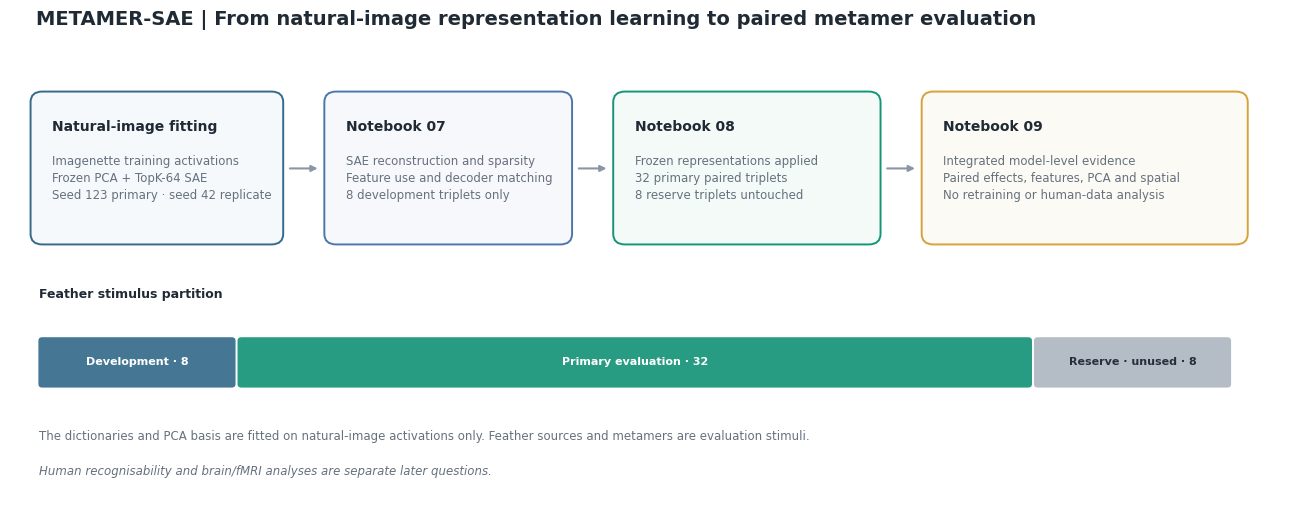

In [7]:
fig, ax = plt.subplots(figsize=(13, 5.2))
ax.set_xlim(0, 13); ax.set_ylim(0, 5.2); ax.axis('off')

def box(x, y, w, h, title, body, edge, face='#FFFFFF'):
    rect = patches.FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.04,rounding_size=0.12',
                                  linewidth=1.4,edgecolor=edge,facecolor=face)
    ax.add_patch(rect)
    ax.text(x+.18,y+h-.28,title,fontsize=10,fontweight='bold',color=COLORS['ink'],va='top')
    ax.text(x+.18,y+h-.68,body,fontsize=8.5,color=COLORS['muted'],va='top',linespacing=1.4)

box(.25,3.0,2.5,1.65,'Natural-image fitting',
    'Imagenette training activations\nFrozen PCA + TopK-64 SAE\nSeed 123 primary · seed 42 replicate',COLORS['source'],'#F5F9FC')
box(3.25,3.0,2.45,1.65,'Notebook 07',
    'SAE reconstruction and sparsity\nFeature use and decoder matching\n8 development triplets only',COLORS['pca_16'],'#F7F8FC')
box(6.2,3.0,2.65,1.65,'Notebook 08',
    'Frozen representations applied\n32 primary paired triplets\n8 reserve triplets untouched',COLORS['adversarial'],'#F4FAF8')
box(9.35,3.0,3.25,1.65,'Notebook 09',
    'Integrated model-level evidence\nPaired effects, features, PCA and spatial\nNo retraining or human-data analysis',COLORS['sae_seed42'],'#FCFAF4')
for x1,x2 in [(2.75,3.25),(5.7,6.2),(8.85,9.35)]:
    ax.annotate('',xy=(x2-.08,3.82),xytext=(x1+.08,3.82),
                arrowprops=dict(arrowstyle='-|>',lw=1.5,color='#8A96A3'))

# Fixed split strip
ax.text(.3,2.35,'Feather stimulus partition',fontsize=9,fontweight='bold',color=COLORS['ink'])
segments=[('Development',8,COLORS['source']),('Primary evaluation',32,COLORS['adversarial']),('Reserve · unused',8,'#AEB7C2')]
start=.3; total=48; fullw=12.2
for label,n,color in segments:
    w=fullw*n/total
    ax.add_patch(patches.FancyBboxPatch((start,1.35),w-.04,.55,boxstyle='round,pad=0.01,rounding_size=.04',
                                        facecolor=color,edgecolor='none',alpha=.92))
    ax.text(start+(w-.04)/2,1.63,f'{label} · {n}',ha='center',va='center',fontsize=8,
            color='white' if color != '#AEB7C2' else '#24303B',fontweight='semibold')
    start += w
ax.text(.3,.75,'The dictionaries and PCA basis are fitted on natural-image activations only. Feather sources and metamers are evaluation stimuli.',
        fontsize=8.5,color=COLORS['muted'])
ax.text(.3,.35,'Human recognisability and brain/fMRI analyses are separate later questions.',fontsize=8.5,color=COLORS['muted'],style='italic')
fig.suptitle('METAMER-SAE | From natural-image representation learning to paired metamer evaluation',
             x=.03,y=.98,ha='left',fontsize=14,fontweight='bold')
fig.tight_layout()
save_figure(fig,'figure_01_evidence_map_and_split_hygiene')

## 6. Figure 2 — TopK dictionary utilisation on natural images

TopK-64 fixes the number of active features per input at 64; it does **not** guarantee that all 1,536 dictionary atoms are used across the dataset. This figure summarises the active/dead feature counts and the distribution of feature activation density in the Imagenette training and validation splits.

Saved: figure_02_natural_feature_utilisation.png and figure_02_natural_feature_utilisation.pdf


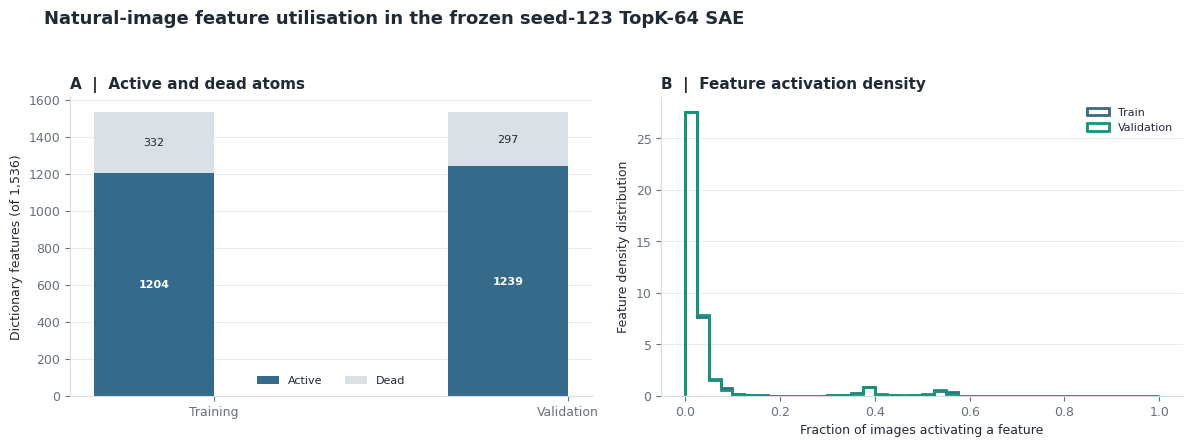

In [8]:
fig, axes = plt.subplots(1,2,figsize=(12,4.5))

# Active/dead feature counts
x=np.arange(2); width=.34
for j, split in enumerate(['train','validation']):
    row=util_n07[util_n07.split==split].iloc[0]
    axes[0].bar(j-.17,row['active_features'],width,color=COLORS['source'],label='Active' if j==0 else None)
    axes[0].bar(j-.17,row['dead_features'],width,bottom=row['active_features'],color='#D9E0E6',label='Dead' if j==0 else None)
    axes[0].text(j-.17,row['active_features']/2,f"{int(row['active_features'])}",ha='center',va='center',color='white',fontsize=8,fontweight='bold')
    axes[0].text(j-.17,row['active_features']+row['dead_features']/2,f"{int(row['dead_features'])}",ha='center',va='center',color=COLORS['ink'],fontsize=8)
axes[0].set_xticks(x,['Training','Validation']); axes[0].set_ylabel('Dictionary features (of 1,536)')
axes[0].set_title('A  |  Active and dead atoms',loc='left'); axes[0].legend(frameon=False,ncol=2)
style_axis(axes[0])

# Activation density distribution
for split,color,label in [('train',COLORS['source'],'Train'),('validation',COLORS['adversarial'],'Validation')]:
    d=feature_stats_n07.loc[feature_stats_n07.split==split,'activation_density'].to_numpy(float)
    axes[1].hist(d,bins=np.linspace(0,1,41),density=True,histtype='step',linewidth=2,color=color,label=label)
axes[1].set_xlabel('Fraction of images activating a feature'); axes[1].set_ylabel('Feature density distribution')
axes[1].set_title('B  |  Feature activation density',loc='left'); axes[1].legend(frameon=False)
style_axis(axes[1])
fig.suptitle('Natural-image feature utilisation in the frozen seed-123 TopK-64 SAE',x=.04,ha='left',fontsize=13,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.93])
save_figure(fig,'figure_02_natural_feature_utilisation')

## 7. Figure 3 — Feature-mass concentration and cross-seed decoder matching

The first panel shows how concentrated total activation mass is among seed-123 features. The second shows Hungarian-matched decoder cosine similarities between the two independently trained dictionaries. Matching is approximate and is not evidence that feature indices or semantic identities coincide.

Saved: figure_03_feature_concentration_and_seed_matching.png and figure_03_feature_concentration_and_seed_matching.pdf


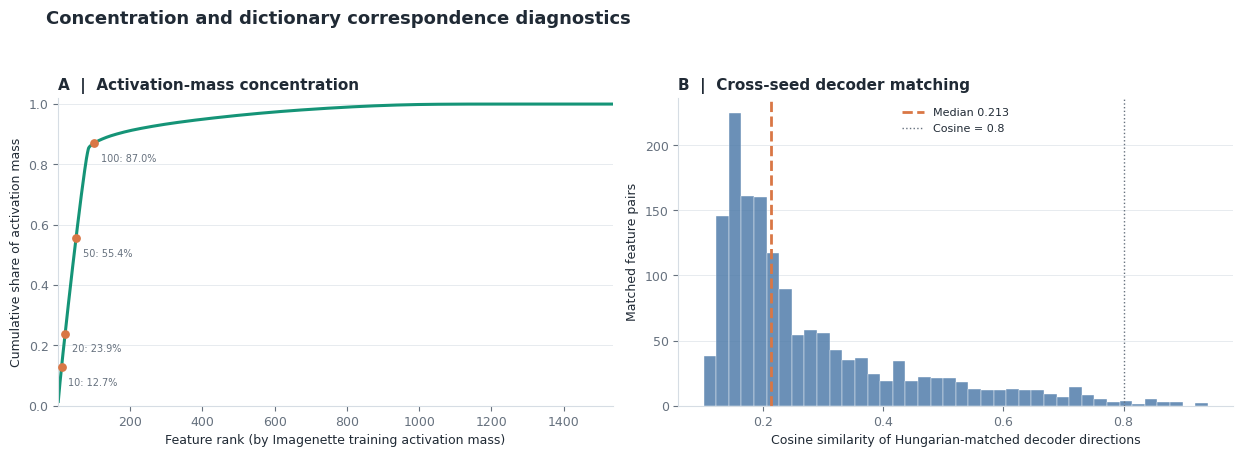

Decoder matching summary:
Matched atoms: 1536 mean: 0.2768 median: 0.2134 q10: 0.1404 q90: 0.5235 fraction >= .8: 0.0117


In [9]:
fig,axes=plt.subplots(1,2,figsize=(12.5,4.6))
rank=feature_mass_n07.sort_values('rank')
axes[0].plot(rank['rank'],rank['cumulative_mass_share'],color=COLORS['sae_seed123'],lw=2.2)
axes[0].set_xlim(1,len(rank)); axes[0].set_ylim(0,1.02)
axes[0].set_xlabel('Feature rank (by Imagenette training activation mass)')
axes[0].set_ylabel('Cumulative share of activation mass')
axes[0].set_title('A  |  Activation-mass concentration',loc='left')
for n in [10,20,50,100]:
    if n<=len(rank):
        v=float(rank.iloc[n-1]['cumulative_mass_share'])
        axes[0].scatter([n],[v],s=28,color=COLORS['standard'],zorder=3)
        axes[0].annotate(f'{n}: {v:.1%}',(n,v),xytext=(5,-13),textcoords='offset points',fontsize=7,color=COLORS['muted'])
style_axis(axes[0])

cos=cross_seed_n07['decoder_cosine_similarity'].to_numpy(float)
axes[1].hist(cos,bins=40,color=COLORS['pca_16'],alpha=.82,edgecolor='white',linewidth=.35)
axes[1].axvline(np.median(cos),color=COLORS['standard'],lw=2,ls='--',label=f'Median {np.median(cos):.3f}')
axes[1].axvline(.8,color=COLORS['muted'],lw=1,ls=':',label='Cosine = 0.8')
axes[1].set_xlabel('Cosine similarity of Hungarian-matched decoder directions')
axes[1].set_ylabel('Matched feature pairs'); axes[1].set_title('B  |  Cross-seed decoder matching',loc='left')
axes[1].legend(frameon=False); style_axis(axes[1])
fig.suptitle('Concentration and dictionary correspondence diagnostics',x=.04,ha='left',fontsize=13,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.93])
save_figure(fig,'figure_03_feature_concentration_and_seed_matching')

print('Decoder matching summary:')
print('Matched atoms:',len(cos),'mean:',round(float(np.mean(cos)),4),'median:',round(float(np.median(cos)),4),
      'q10:',round(float(np.quantile(cos,.10)),4),'q90:',round(float(np.quantile(cos,.90)),4),
      'fraction >= .8:',round(float(np.mean(cos>=.8)),4))

## 8. Figure 4 — Paired source-to-metamer L2 distances for all primary triplets

Each line connects the standard and adversarial metamer generated from the same source. Panels use independent y-scales because raw L2 values are not commensurate across the five coordinate systems. The direction-consistency check shows all 32 lines slope from the higher standard distance to the lower adversarial distance in every panel.

Saved: figure_04_primary_triplet_paired_l2_distances.png and figure_04_primary_triplet_paired_l2_distances.pdf


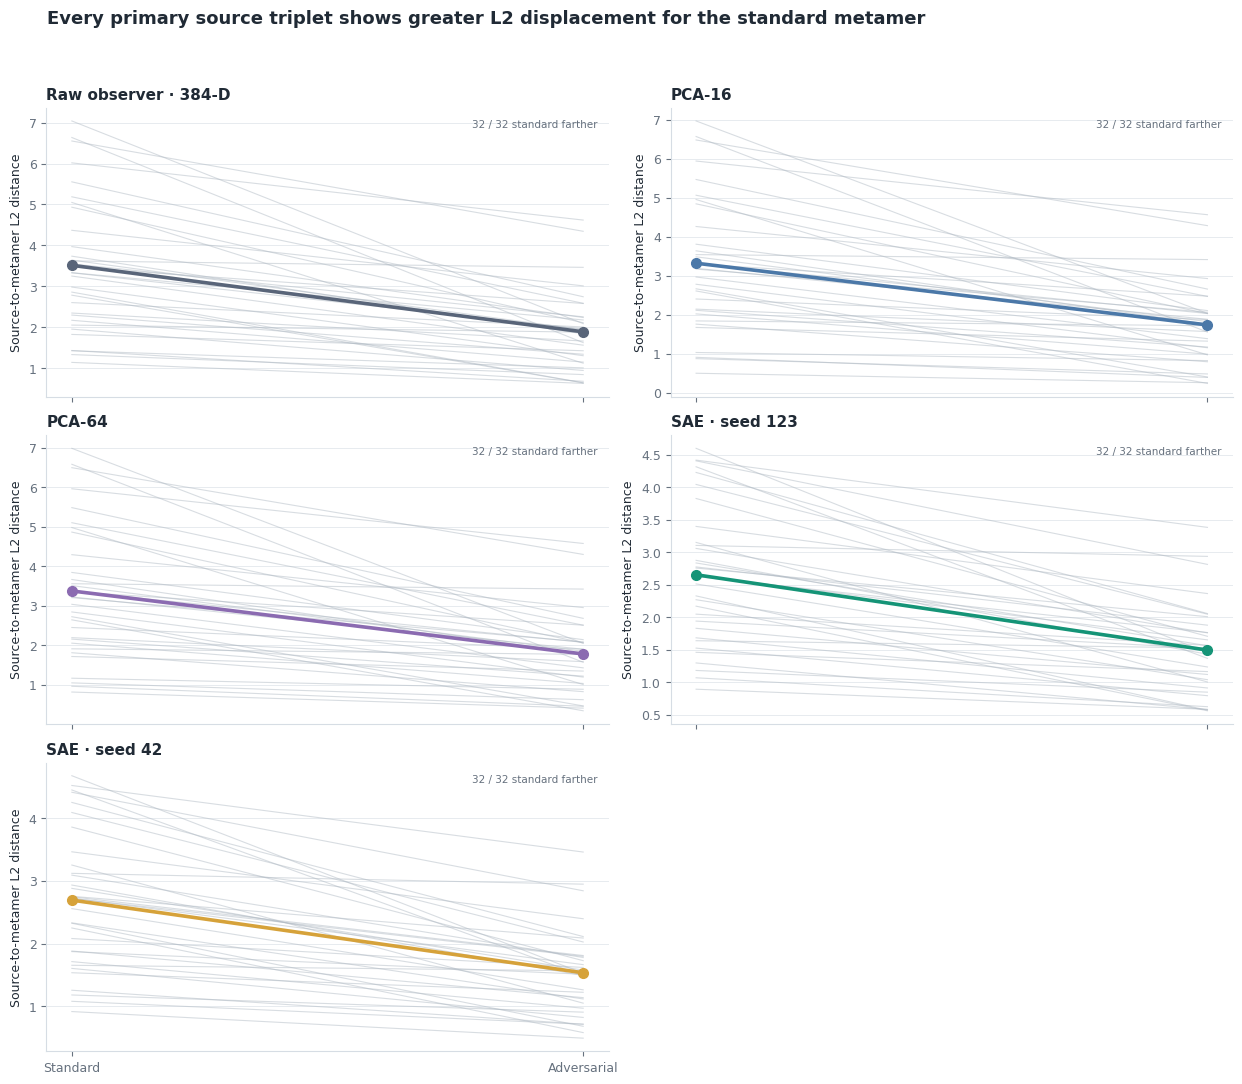

In [10]:
fig,axes=plt.subplots(3,2,figsize=(12.5,11),sharex=True)
axes=axes.ravel()
for ax,rep in zip(axes,REPRESENTATIONS):
    sub=primary_pair[primary_pair.representation==rep]
    wide=sub.pivot(index='stimulus_id',columns='metamer_condition',values='distance_l2')
    wide=wide.sort_index()
    for _,row in wide.iterrows():
        ax.plot([0,1],[row['standard'],row['adversarial']],color='#AEB8C2',alpha=.48,lw=.8,zorder=1)
    means=[wide['standard'].mean(),wide['adversarial'].mean()]
    ax.plot([0,1],means,color=COLORS[rep],lw=2.6,marker='o',markersize=7,zorder=3)
    ax.set_xticks([0,1],['Standard','Adversarial'])
    ax.set_ylabel('Source-to-metamer L2 distance')
    ax.set_title(LABELS[rep],loc='left')
    ax.text(.98,.96,'32 / 32 standard farther',transform=ax.transAxes,ha='right',va='top',fontsize=7.5,color=COLORS['muted'])
    style_axis(ax)
axes[-1].axis('off')
fig.suptitle('Every primary source triplet shows greater L2 displacement for the standard metamer',
             x=.04,ha='left',fontsize=13,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.95])
save_figure(fig,'figure_04_primary_triplet_paired_l2_distances')

## 9. Figure 5 — Standard-versus-adversarial paired effects

The forest plots show the mean paired contrast and its triplet-bootstrap 95% interval. Positive values indicate greater displacement for standard metamers. L2 and relative L2 are shown separately; do not compare the absolute horizontal scales between panels.

Saved: figure_05_paired_effects_l2_and_relative_l2.png and figure_05_paired_effects_l2_and_relative_l2.pdf


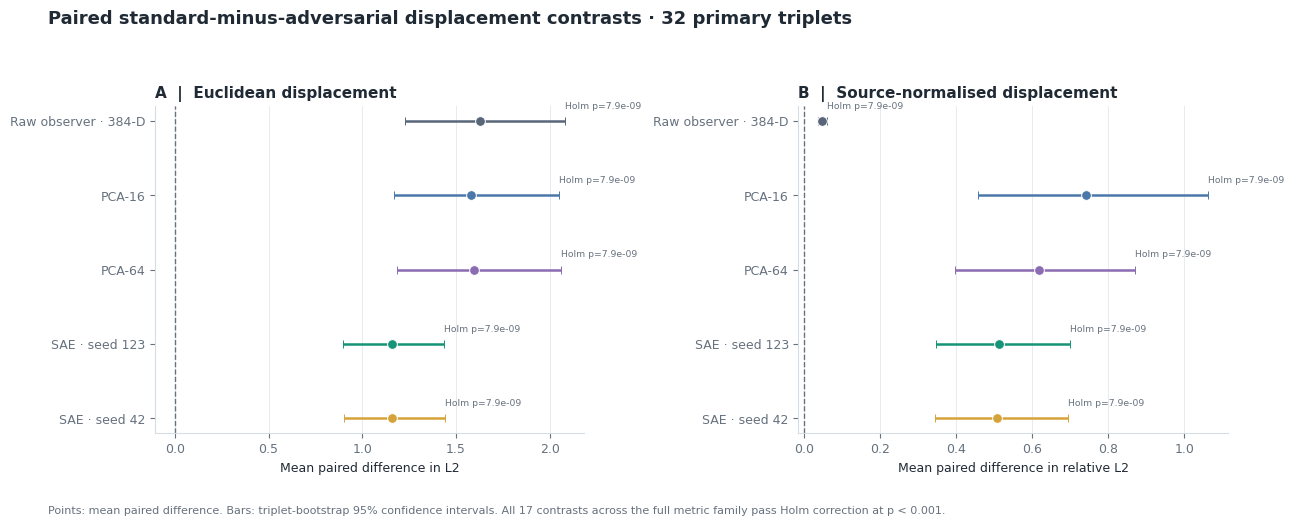

In [11]:
def contrast_subset(metric_phrase):
    q=contrasts[contrasts['contrast'].str.contains(metric_phrase,case=False,regex=False)].copy()
    q['representation']=q['contrast'].str.split(':').str[0]
    q=q.set_index('representation').loc[REPRESENTATIONS].reset_index()
    for col in ['mean_paired_difference','bootstrap_95ci_low','bootstrap_95ci_high','wilcoxon_p_holm']:
        q[col]=pd.to_numeric(q[col])
    return q

l2_effects=contrast_subset('L2 distance')
rel_effects=contrast_subset('relative L2')
fig,axes=plt.subplots(1,2,figsize=(13,5.2))
for ax,data,title,xlabel in [
    (axes[0],l2_effects,'A  |  Euclidean displacement','Mean paired difference in L2'),
    (axes[1],rel_effects,'B  |  Source-normalised displacement','Mean paired difference in relative L2')]:
    ypos=np.arange(len(data))[::-1]
    for y,row in zip(ypos,data.to_dict('records')):
        rep=row['representation']; m=row['mean_paired_difference']
        lo=row['bootstrap_95ci_low']; hi=row['bootstrap_95ci_high']
        ax.errorbar(m,y,xerr=[[m-lo],[hi-m]],fmt='o',ms=7,capsize=3,lw=1.8,
                    color=COLORS[rep],markeredgecolor='white',markeredgewidth=.7)
        ax.text(hi,y+.17,f"Holm p={row['wilcoxon_p_holm']:.1e}",fontsize=6.7,color=COLORS['muted'])
    ax.axvline(0,color=COLORS['muted'],ls='--',lw=1)
    ax.set_yticks(ypos,[LABELS[r] for r in data['representation']])
    ax.set_xlabel(xlabel); ax.set_title(title,loc='left'); style_axis(ax,'x')
fig.suptitle('Paired standard-minus-adversarial displacement contrasts · 32 primary triplets',
             x=.04,ha='left',fontsize=13,fontweight='bold')
fig.text(.04,.01,'Points: mean paired difference. Bars: triplet-bootstrap 95% confidence intervals. All 17 contrasts across the full metric family pass Holm correction at p < 0.001.',
         fontsize=8,color=COLORS['muted'])
fig.tight_layout(rect=[0,.06,1,.92])
save_figure(fig,'figure_05_paired_effects_l2_and_relative_l2')

## 10. Figure 6 — Cosine differences and distributional asymmetry

The mean and median paired cosine differences are plotted together. The contrast table shows that some PCA and SAE cosine means are much larger than their medians. This is a warning against describing the mean as the typical triplet effect without inspecting the underlying distribution.

Saved: figure_06_cosine_paired_difference_distribution.png and figure_06_cosine_paired_difference_distribution.pdf


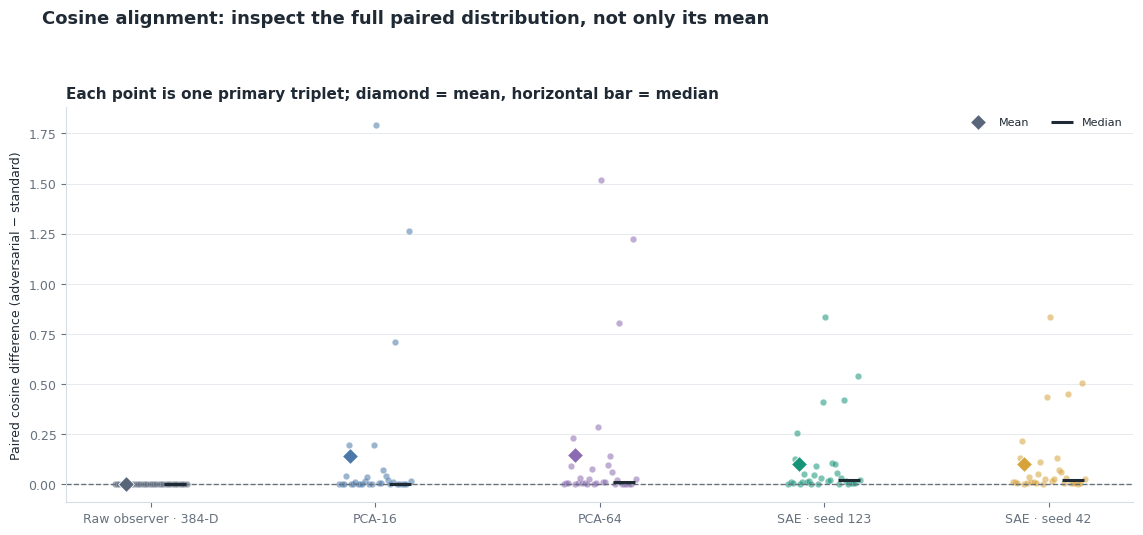

,representation,mean,median,q10,q90,min,max
0,raw_384,0.000341,0.000319,0.000148,0.000493,0.000065,0.000766
1,pca_16,0.139120,0.003624,0.000319,0.196620,-0.000221,1.792296
2,pca_64,0.147163,0.009358,0.001344,0.281157,0.000418,1.516582
3,sae_seed123,0.102127,0.019306,0.002870,0.393921,0.000463,0.835192
4,sae_seed42,0.101567,0.019053,0.004000,0.411762,0.002465,0.832303


In [12]:
fig,ax=plt.subplots(figsize=(11.5,5.4))
cos_rows=[]
for rep in REPRESENTATIONS:
    sub=primary_pair[primary_pair.representation==rep]
    wide=sub.pivot(index='stimulus_id',columns='metamer_condition',values='cosine_similarity')
    d=(wide['adversarial']-wide['standard']).to_numpy(float)
    cos_rows.append({'representation':rep,'mean':float(np.mean(d)),'median':float(np.median(d)),
                     'q10':float(np.quantile(d,.1)),'q90':float(np.quantile(d,.9)),
                     'min':float(np.min(d)),'max':float(np.max(d))})
    x=REPRESENTATIONS.index(rep)
    jitter=np.linspace(-.16,.16,len(d))
    ax.scatter(x+jitter,d,s=22,color=COLORS[rep],alpha=.55,edgecolor='white',linewidth=.25,zorder=2)
    ax.scatter([x-.11],[np.mean(d)],marker='D',s=65,color=COLORS[rep],edgecolor='white',linewidth=.6,zorder=4,label='Mean' if x==0 else None)
    ax.scatter([x+.11],[np.median(d)],marker='_',s=260,color=COLORS['ink'],linewidth=2.2,zorder=5,label='Median' if x==0 else None)
ax.axhline(0,color=COLORS['muted'],ls='--',lw=1)
ax.set_xticks(np.arange(len(REPRESENTATIONS)),[LABELS[r] for r in REPRESENTATIONS])
ax.set_ylabel('Paired cosine difference (adversarial − standard)')
ax.set_title('Each point is one primary triplet; diamond = mean, horizontal bar = median',loc='left')
ax.legend(frameon=False,ncol=2); style_axis(ax)
fig.suptitle('Cosine alignment: inspect the full paired distribution, not only its mean',x=.04,ha='left',fontsize=13,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.92])
save_figure(fig,'figure_06_cosine_paired_difference_distribution')
cosine_distribution_summary=pd.DataFrame(cos_rows)
display(cosine_distribution_summary.round(6))

## 11. Figure 7 — SAE active-support overlap

The Jaccard score measures overlap between the active TopK feature sets of a source and its paired metamer. The two seed dictionaries are evaluated in their own feature spaces. Lines pair conditions within a source triplet; the notebook never matches a seed-123 feature ID to the same numerical seed-42 ID.

Saved: figure_07_sae_support_overlap_paired.png and figure_07_sae_support_overlap_paired.pdf


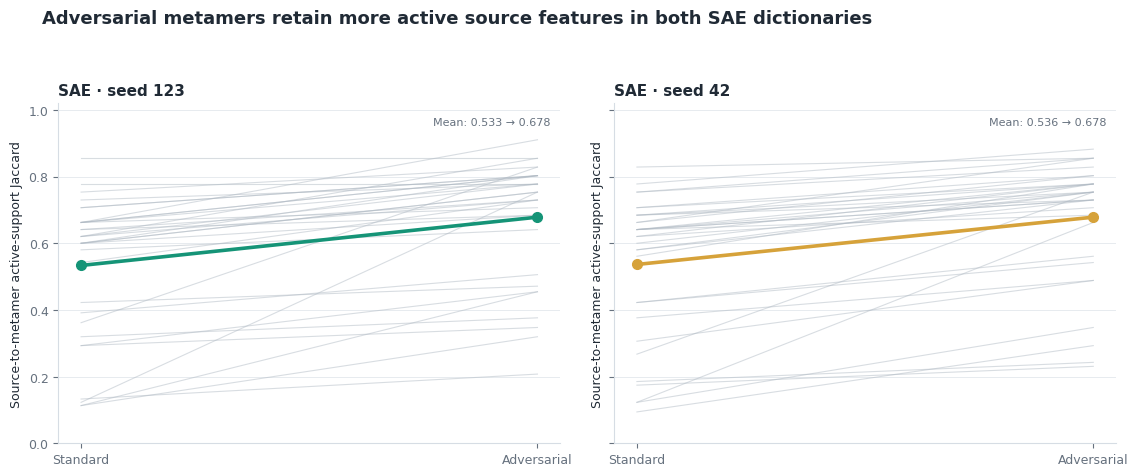

In [13]:
fig,axes=plt.subplots(1,2,figsize=(11.5,4.8),sharey=True)
for ax,rep in zip(axes,['sae_seed123','sae_seed42']):
    sub=primary_pair[primary_pair.representation==rep]
    wide=sub.pivot(index='stimulus_id',columns='metamer_condition',values='support_jaccard').sort_index()
    for _,row in wide.iterrows():
        ax.plot([0,1],[row['standard'],row['adversarial']],color='#AEB8C2',alpha=.48,lw=.8)
    means=[wide['standard'].mean(),wide['adversarial'].mean()]
    ax.plot([0,1],means,color=COLORS[rep],marker='o',lw=2.6,ms=7)
    ax.set_xticks([0,1],['Standard','Adversarial']); ax.set_ylim(0,1.02)
    ax.set_ylabel('Source-to-metamer active-support Jaccard')
    ax.set_title(LABELS[rep],loc='left')
    ax.text(.98,.96,f"Mean: {means[0]:.3f} → {means[1]:.3f}",transform=ax.transAxes,ha='right',va='top',fontsize=8,color=COLORS['muted'])
    style_axis(ax)
fig.suptitle('Adversarial metamers retain more active source features in both SAE dictionaries',
             x=.04,ha='left',fontsize=13,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.92])
save_figure(fig,'figure_07_sae_support_overlap_paired')

## 12. Figure 8 — Reconstruction error by representation and paired MSE change

The first panel reports source, standard and adversarial reconstruction error in each frozen representation. The second focuses on the paired quantity `metamer MSE − source MSE`: positive means greater reconstruction error for the metamer. These are representation-specific residual measurements; they are not direct measures of human perceptual quality.

Saved: figure_08_reconstruction_error_geometry.png and figure_08_reconstruction_error_geometry.pdf


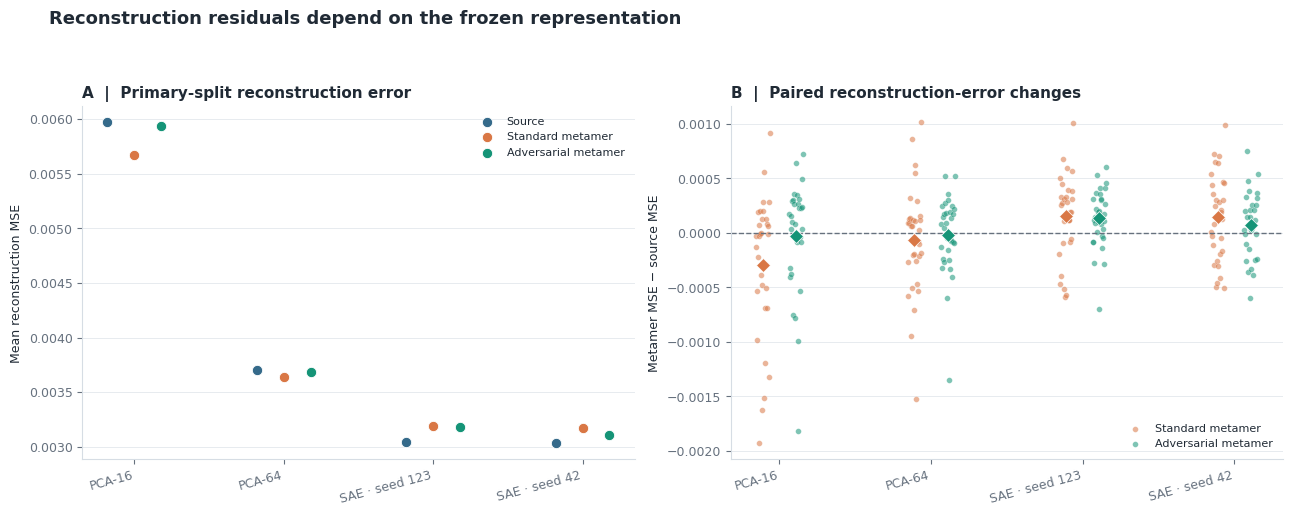

,representation,metamer_condition,n_triplets,mean_delta_reconstruction_mse,median_delta_reconstruction_mse,bootstrap_95ci_low,bootstrap_95ci_high
1,pca_16,adversarial,32,-0.000029,0.000092,-0.000213,0.000139
0,pca_16,standard,32,-0.000295,-0.000029,-0.000529,-0.000080
3,pca_64,adversarial,32,-0.000015,0.000062,-0.000143,0.000099
2,pca_64,standard,32,-0.000062,0.000044,-0.000235,0.000108
5,sae_seed123,adversarial,32,0.000136,0.000142,0.000042,0.000223
4,sae_seed123,standard,32,0.000153,0.000196,0.000024,0.000281
7,sae_seed42,adversarial,32,0.000075,0.000083,-0.000029,0.000174
6,sae_seed42,standard,32,0.000144,0.000170,0.000008,0.000278


In [14]:
methods=['pca_16','pca_64','sae_seed123','sae_seed42']
fig,axes=plt.subplots(1,2,figsize=(13,5.2))

# Primary-split reconstruction MSE means from Notebook 08.
summary=recon_summary[recon_summary.representation.isin(methods)].copy()
summary['representation']=pd.Categorical(summary['representation'],categories=methods,ordered=True)
summary=summary.sort_values('representation')
for i,rep in enumerate(methods):
    q=summary[summary.representation==rep].set_index('condition')
    for j,cond in enumerate(['source','standard','adversarial']):
        if cond in q.index:
            axes[0].scatter(i+(j-1)*.18,q.loc[cond,'mean_mse'],s=55,color=COLORS[cond],edgecolor='white',linewidth=.6,
                            label=CONDITION_LABELS[cond] if i==0 else None,zorder=3)
axes[0].set_xticks(range(len(methods)),[LABELS[m] for m in methods],rotation=15,ha='right')
axes[0].set_ylabel('Mean reconstruction MSE'); axes[0].set_title('A  |  Primary-split reconstruction error',loc='left')
axes[0].legend(frameon=False); style_axis(axes[0])

# Paired MSE changes and triplet-level observations.
for i,rep in enumerate(methods):
    for j,cond in enumerate(['standard','adversarial']):
        vals=primary_pair.loc[(primary_pair.representation==rep)&(primary_pair.metamer_condition==cond),'delta_reconstruction_error'].to_numpy(float)
        x=i+(j-.5)*.22
        jitter=np.linspace(-.045,.045,len(vals))
        axes[1].scatter(x+jitter,vals,s=17,color=COLORS[cond],alpha=.55,edgecolor='white',linewidth=.25,
                        label=CONDITION_LABELS[cond] if i==0 else None)
        axes[1].scatter([x],[np.mean(vals)],marker='D',s=50,color=COLORS[cond],edgecolor='white',linewidth=.5,zorder=4)
axes[1].axhline(0,color=COLORS['muted'],ls='--',lw=1)
axes[1].set_xticks(range(len(methods)),[LABELS[m] for m in methods],rotation=15,ha='right')
axes[1].set_ylabel('Metamer MSE − source MSE'); axes[1].set_title('B  |  Paired reconstruction-error changes',loc='left')
axes[1].legend(frameon=False); style_axis(axes[1])
fig.suptitle('Reconstruction residuals depend on the frozen representation',x=.04,ha='left',fontsize=13,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.92])
save_figure(fig,'figure_08_reconstruction_error_geometry')

display(recon_deltas.sort_values(['representation','metamer_condition']).round(8))

## 13. Figure 9 — Natural-training-ranked SAE feature changes

The seed-123 feature ranking was fixed using activation mass on Imagenette training data only. This figure shows signed mean metamer-minus-source changes for the 30 highest-ranked natural-training features, separately for standard and adversarial metamers. Feature IDs are shown only for seed 123; the seed-42 dictionary is not indexed against it.

Saved: figure_09_seed123_natural_ranked_feature_changes.png and figure_09_seed123_natural_ranked_feature_changes.pdf


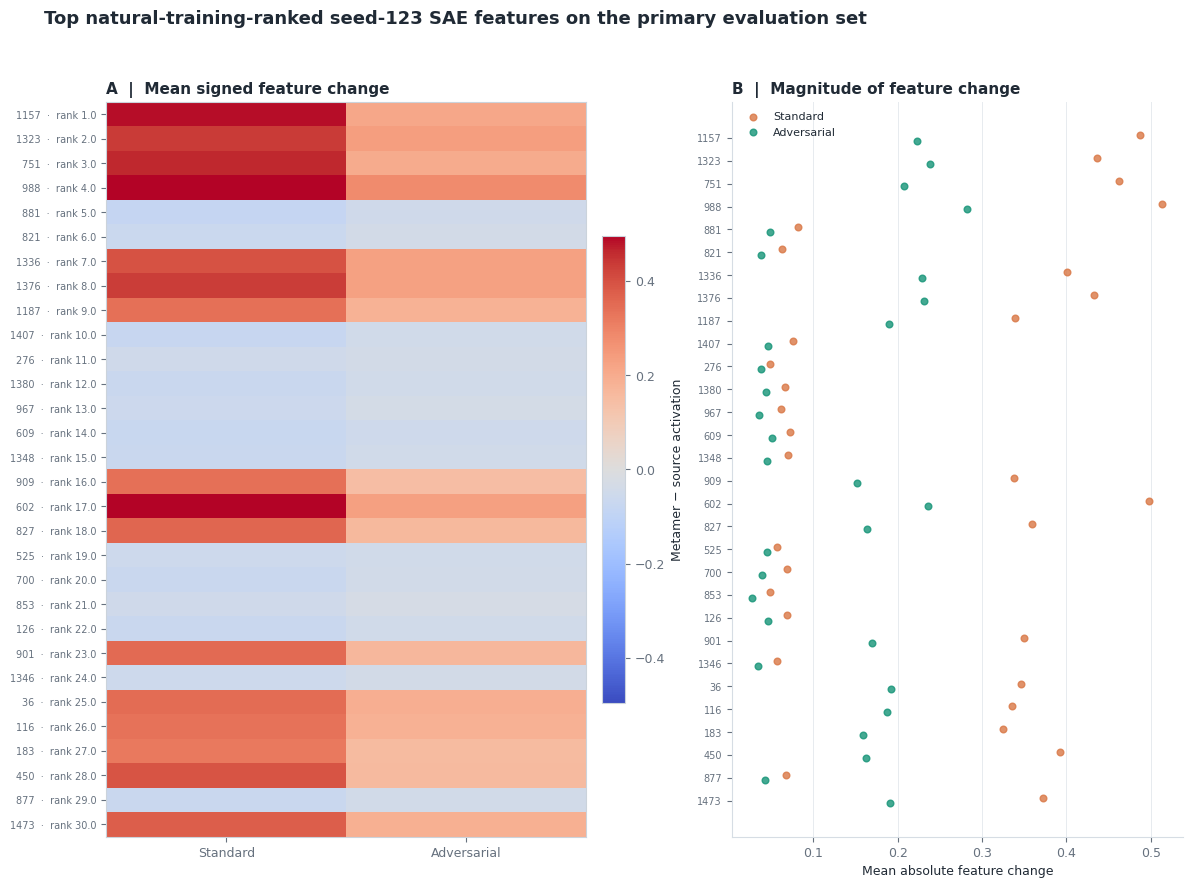

In [15]:
rank_top=natural_feature_rank.sort_values('natural_train_mass_rank').head(30).copy()
rank_top['feature_id_seed123']=rank_top['feature_id_seed123'].astype(int)
fc=feature_change_123.copy()
fc['feature_id']=fc['feature_id'].astype(int)
fc['metamer_condition']=fc['metamer_condition'].astype(str)
fc=fc[fc.feature_id.isin(rank_top.feature_id_seed123)]
wide_signed=fc.pivot(index='feature_id',columns='metamer_condition',values='mean_signed_change')
wide_abs=fc.pivot(index='feature_id',columns='metamer_condition',values='mean_absolute_change')
ordered=rank_top.feature_id_seed123.to_list()
wide_signed=wide_signed.reindex(ordered)
wide_abs=wide_abs.reindex(ordered)

vals=wide_signed[['standard','adversarial']].to_numpy(float)
lim=float(np.nanquantile(np.abs(vals),.98))
lim=max(lim,1e-8)
fig,axes=plt.subplots(1,2,figsize=(12,9),gridspec_kw={'width_ratios':[1.15,1]})
im=axes[0].imshow(vals,aspect='auto',cmap='coolwarm',norm=TwoSlopeNorm(vmin=-lim,vcenter=0,vmax=lim),interpolation='nearest')
axes[0].set_yticks(np.arange(len(ordered)),[f"{fid}  ·  rank {rank_top.iloc[i].natural_train_mass_rank}" for i,fid in enumerate(ordered)],fontsize=7)
axes[0].set_xticks([0,1],['Standard','Adversarial'])
axes[0].set_title('A  |  Mean signed feature change',loc='left')
cb=fig.colorbar(im,ax=axes[0],fraction=.045,pad=.03); cb.set_label('Metamer − source activation')

# Absolute-change profiles, with one pair of points per feature.
y=np.arange(len(ordered))
for cond,color,offset,label in [('standard',COLORS['standard'],-.12,'Standard'),('adversarial',COLORS['adversarial'],.12,'Adversarial')]:
    axes[1].scatter(wide_abs.loc[ordered,cond],y+offset,s=23,color=color,alpha=.8,label=label)
axes[1].set_yticks(y,[str(fid) for fid in ordered],fontsize=7)
axes[1].invert_yaxis(); axes[1].set_xlabel('Mean absolute feature change')
axes[1].set_title('B  |  Magnitude of feature change',loc='left'); axes[1].legend(frameon=False)
style_axis(axes[1],'x')
fig.suptitle('Top natural-training-ranked seed-123 SAE features on the primary evaluation set',
             x=.04,ha='left',fontsize=13,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.95])
save_figure(fig,'figure_09_seed123_natural_ranked_feature_changes')

## 14. Figure 10 — Feature-change distribution across SAE seeds

This comparison is distributional. It compares the marginal distribution of mean absolute feature changes across each dictionary, without asserting that feature 17 in one seed corresponds to feature 17 in the other. This is a suitable aggregate robustness view when direct feature identity is not stable.

Saved: figure_10_sae_feature_change_ecdf_by_seed.png and figure_10_sae_feature_change_ecdf_by_seed.pdf


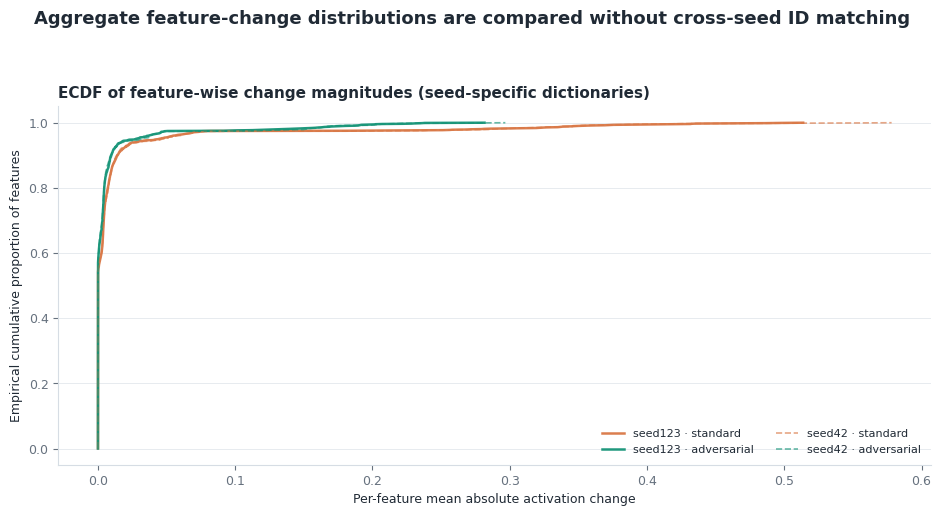

In [16]:
fig,ax=plt.subplots(figsize=(9.5,5.2))
for frame,seed in [(feature_change_123,'seed123'),(feature_change_42,'seed42')]:
    for cond in ['standard','adversarial']:
        vals=np.sort(frame.loc[frame.metamer_condition==cond,'mean_absolute_change'].to_numpy(float))
        y=np.arange(1,len(vals)+1)/len(vals)
        ax.plot(vals,y,color=COLORS[cond],lw=1.8 if seed=='seed123' else 1.2,
                ls='-' if seed=='seed123' else '--',alpha=.95 if seed=='seed123' else .65,
                label=f'{seed} · {cond}')
ax.set_xlabel('Per-feature mean absolute activation change')
ax.set_ylabel('Empirical cumulative proportion of features')
ax.set_title('ECDF of feature-wise change magnitudes (seed-specific dictionaries)',loc='left')
ax.legend(frameon=False,ncol=2); style_axis(ax)
fig.suptitle('Aggregate feature-change distributions are compared without cross-seed ID matching',
             x=.04,ha='left',fontsize=13,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.92])
save_figure(fig,'figure_10_sae_feature_change_ecdf_by_seed')

## 15. Figure 11 — Standardised PCA component displacement profiles

Notebook 08 scales each component displacement by that component's standard deviation on natural training data. The plot describes how source-to-metamer displacement is distributed across the retained PCA spectrum. It does not assign semantic labels to individual principal components.

Saved: figure_11_pca_component_displacement_profiles.png and figure_11_pca_component_displacement_profiles.pdf


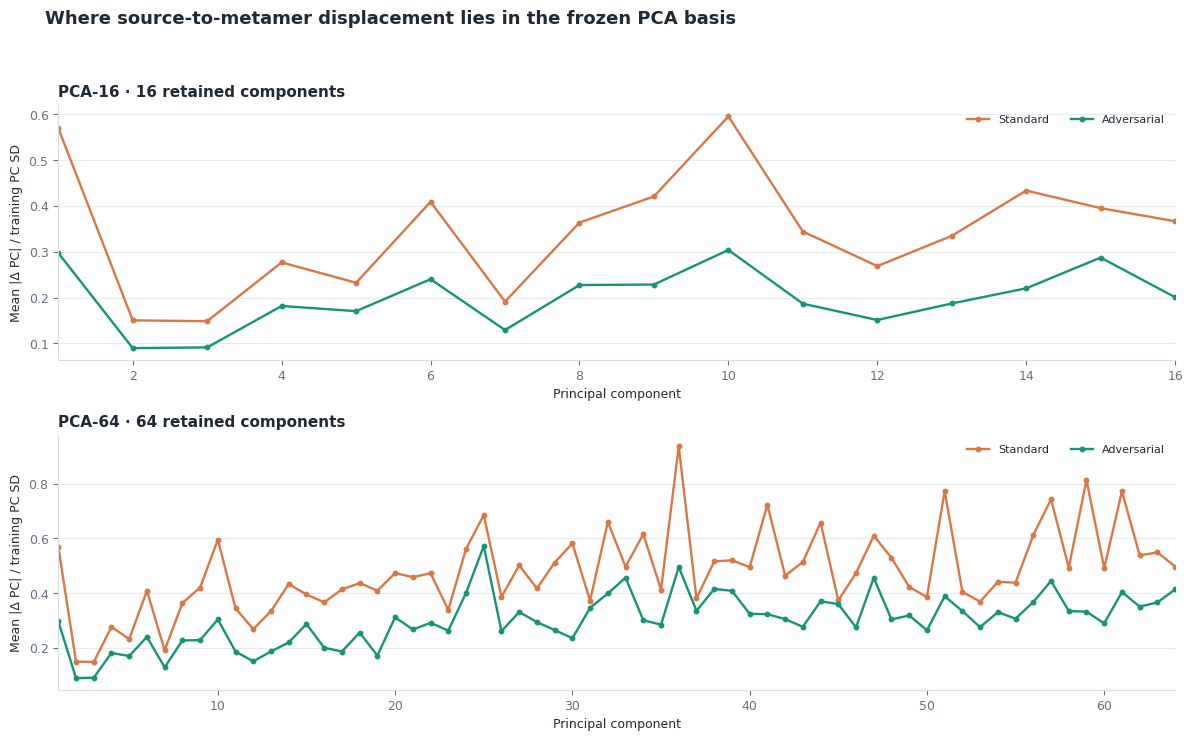

In [17]:
fig,axes=plt.subplots(2,1,figsize=(12,7.5))
for ax,rep,k in zip(axes,['pca_16','pca_64'],[16,64]):
    q=pca_profiles[(pca_profiles.split=='primary_evaluation')&(pca_profiles.representation==rep)]
    for cond,color in [('standard',COLORS['standard']),('adversarial',COLORS['adversarial'])]:
        d=q[q.metamer_condition==cond].sort_values('component')
        ax.plot(d.component,d.mean_absolute_delta_pc_sd,marker='o',ms=3.2,lw=1.7,color=color,label=cond.capitalize())
    ax.set_xlim(1,k); ax.set_xlabel('Principal component')
    ax.set_ylabel('Mean |Δ PC| / training PC SD')
    ax.set_title(f'{LABELS[rep]} · {k} retained components',loc='left')
    ax.legend(frameon=False,ncol=2); style_axis(ax)
fig.suptitle('Where source-to-metamer displacement lies in the frozen PCA basis',
             x=.04,ha='left',fontsize=13,fontweight='bold')
fig.tight_layout(rect=[0,0,1,.94])
save_figure(fig,'figure_11_pca_component_displacement_profiles')

## 16. Figure 12 — Raw observer spatial diagnostic (if available)

This is a separate diagnostic using the unpooled ConvNeXt-Tiny Stage-3 activation maps. It is **not** a spatial SAE analysis: the TopK SAE in this project was trained on pooled 384-D image-level vectors and has no retained 14×14 feature coordinates.

/tmp/ipykernel_364/3725836920.py:17: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0,0,1,.92])


Saved: figure_12_raw_observer_spatial_diagnostics.png and figure_12_raw_observer_spatial_diagnostics.pdf


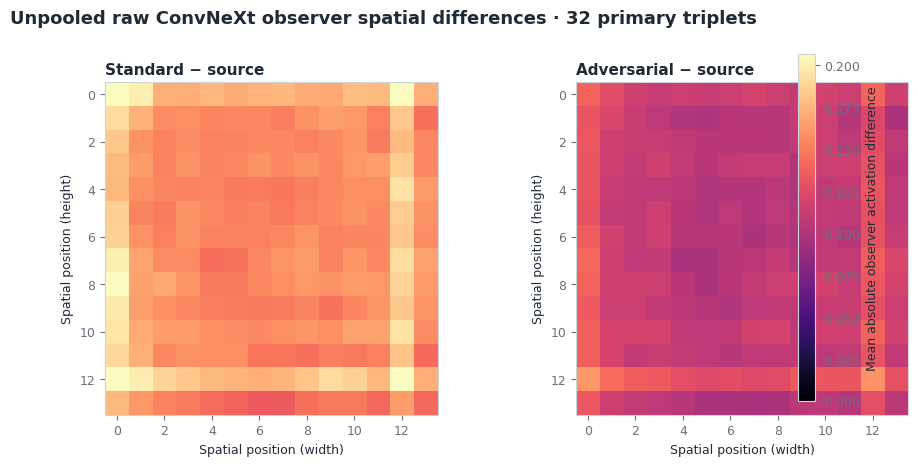

observer_spatial_l2  \
split              metamer_condition                        
development        adversarial                  76.615263   
                   standard                    108.439085   
primary_evaluation adversarial                  75.352841   
                   standard                    109.976274   

                                      observer_spatial_relative_l2  \
split              metamer_condition                                 
development        adversarial                            0.144777   
                   standard                               0.202209   
primary_evaluation adversarial                            0.151378   
                   standard                               0.219689   

                                      observer_spatial_cosine  \
split              metamer_condition                            
development        adversarial                       0.989871   
                   standard                          0.981937   
primary_evaluation adversarial                       0.989251   
                   standard                          0.979047   

                                      observer_spatial_mean_absolute_change  
split              metamer_condition                                         
development        adversarial                                     0.114569  
                   standard                                        0.156426  
primary_evaluation adversarial                                     0.114163  
                   standard                                        0.163536

In [18]:
spatial_map_path=N08_ARRAYS/'primary_evaluation_raw_observer_spatial_difference_maps.npz'
if spatial_map_path.exists():
    z=np.load(spatial_map_path)
    required_keys={'standard','adversarial'}
    assert required_keys.issubset(z.files), f'Unexpected spatial map keys: {z.files}'
    map_std=np.asarray(z['standard'],dtype=float)
    map_adv=np.asarray(z['adversarial'],dtype=float)
    assert map_std.shape==(14,14) and map_adv.shape==(14,14)
    vmax=float(np.quantile(np.concatenate([map_std.ravel(),map_adv.ravel()]),.99))
    fig,axes=plt.subplots(1,2,figsize=(9.5,4.5))
    for ax,data,title in zip(axes,[map_std,map_adv],['Standard − source','Adversarial − source']):
        im=ax.imshow(data,cmap='magma',origin='upper',vmin=0,vmax=vmax,interpolation='nearest')
        ax.set_title(title,loc='left'); ax.set_xlabel('Spatial position (width)'); ax.set_ylabel('Spatial position (height)')
    cb=fig.colorbar(im,ax=axes.ravel().tolist(),fraction=.04,pad=.04); cb.set_label('Mean absolute observer activation difference')
    fig.suptitle('Unpooled raw ConvNeXt observer spatial differences · 32 primary triplets',
                 x=.04,ha='left',fontsize=13,fontweight='bold')
    fig.tight_layout(rect=[0,0,1,.92])
    save_figure(fig,'figure_12_raw_observer_spatial_diagnostics')
    spatial_maps_available=True
else:
    print('Spatial maps were not saved by Notebook 08. This optional diagnostic is skipped; pooled SAE results are unaffected.')
    spatial_maps_available=False

if not spatial_pair.empty:
    display(spatial_pair.groupby(['split','metamer_condition'])[
        ['observer_spatial_l2','observer_spatial_relative_l2','observer_spatial_cosine','observer_spatial_mean_absolute_change']
    ].mean().round(6))

## 17. Cross-seed aggregate robustness and development-only feature responses

This section keeps the two types of cross-seed evidence separate:

1. **Decoder matching** compares atom directions between dictionaries and showed limited one-to-one alignment in Notebook 07.
2. **Aggregate paired results** compare the condition-level source-to-metamer metrics within each dictionary and show close agreement in Notebook 08.

The eight development triplets provide exploratory evidence about feature response patterns and top-feature overlap. They are not merged with the 32 primary triplets to increase the confirmatory sample size.

In [19]:
# Summarise the primary SAE condition metrics by seed without aligning feature IDs.
seed_summary=seed_robustness.copy()
seed_summary['seed']=seed_summary['seed'].astype(str)
for c in ['mean_code_l2','mean_relative_code_l2','mean_code_cosine','mean_support_jaccard']:
    seed_summary[c]=pd.to_numeric(seed_summary[c])

dev_overlap_summary=dev_overlap_n07.copy()
print('Primary SAE seed-level summary:')
display(seed_summary.round(5))
print('Notebook 07 development top-20 feature overlap:')
display(dev_overlap_summary.round(4))

# Pairwise seed difference table for aggregate metrics (same condition, not same feature identity).
seed_wide=seed_summary.pivot(index='metamer_condition',columns='seed',values=['mean_code_l2','mean_relative_code_l2','mean_code_cosine','mean_support_jaccard'])
seed_difference_rows=[]
for metric in ['mean_code_l2','mean_relative_code_l2','mean_code_cosine','mean_support_jaccard']:
    for cond in ['standard','adversarial']:
        a=float(seed_wide.loc[cond,(metric,'seed123')]); b=float(seed_wide.loc[cond,(metric,'seed42')])
        seed_difference_rows.append({'metric':metric,'condition':cond,'seed123':a,'seed42':b,'absolute_seed_difference':abs(a-b)})
seed_aggregate_agreement=pd.DataFrame(seed_difference_rows)
display(seed_aggregate_agreement.round(6))

Primary SAE seed-level summary:


,seed,metamer_condition,n_triplets,mean_code_l2,mean_relative_code_l2,mean_code_cosine,mean_support_jaccard
0,seed123,standard,32,2.65585,1.13165,0.78037,0.53339
1,seed123,adversarial,32,1.49767,0.61941,0.88249,0.67830
2,seed42,standard,32,2.69383,1.13337,0.78284,0.53638
3,seed42,adversarial,32,1.53391,0.62491,0.88441,0.67824


Notebook 07 development top-20 feature overlap:


,condition_a,condition_b,top20_intersection,top20_jaccard
0,source,standard,5,0.1429
1,source,adversarial,5,0.1429
2,standard,adversarial,18,0.8182


,metric,condition,seed123,seed42,absolute_seed_difference
0,mean_code_l2,standard,2.655846,2.693826,0.037980
1,mean_code_l2,adversarial,1.497673,1.533909,0.036236
2,mean_relative_code_l2,standard,1.131646,1.133370,0.001723
3,mean_relative_code_l2,adversarial,0.619410,0.624910,0.005500
4,mean_code_cosine,standard,0.780368,0.782844,0.002476
5,mean_code_cosine,adversarial,0.882495,0.884412,0.001917
6,mean_support_jaccard,standard,0.533393,0.536385,0.002992
7,mean_support_jaccard,adversarial,0.678300,0.678237,0.000062


## 18. Consolidated quantitative tables

The following tables are saved as compact machine-readable synthesis products. The raw primary triplet rows remain available in the Notebook 08 output directory; this notebook saves summaries and does not overwrite them.

In [20]:
# 18.1 L2 and relative-L2 contrasts in a publication-friendly format.
summary_contrasts=contrasts.copy()
summary_contrasts['representation']=summary_contrasts['contrast'].str.split(':').str[0]
summary_contrasts['metric']=summary_contrasts['contrast'].str.split(':',n=1).str[1].str.strip()
for col in ['mean_first','mean_second','mean_paired_difference','median_paired_difference',
            'bootstrap_95ci_low','bootstrap_95ci_high','cohens_dz','wilcoxon_p_two_sided','wilcoxon_p_holm']:
    summary_contrasts[col]=pd.to_numeric(summary_contrasts[col])
summary_contrasts['wilcoxon_p_two_sided_sci']=summary_contrasts['wilcoxon_p_two_sided'].map(lambda x:f'{x:.3e}')
summary_contrasts['wilcoxon_p_holm_sci']=summary_contrasts['wilcoxon_p_holm'].map(lambda x:f'{x:.3e}')

summary_contrasts.to_csv(TABLE_DIR/'integrated_primary_paired_contrasts.csv',index=False)
seed_aggregate_agreement.to_csv(TABLE_DIR/'integrated_sae_seed_aggregate_agreement.csv',index=False)
cosine_distribution_summary.to_csv(TABLE_DIR/'integrated_cosine_distribution_summary.csv',index=False)

# Development/primary direction comparison, preserved as separate rows.
direction_consistency.to_csv(TABLE_DIR/'integrated_direction_consistency.csv',index=False)

print('Saved integrated contrast and robustness tables to:',TABLE_DIR)
display(summary_contrasts[['representation','metric','mean_paired_difference','median_paired_difference',
                           'bootstrap_95ci_low','bootstrap_95ci_high','cohens_dz',
                           'wilcoxon_p_holm_sci']].round(6))

Saved integrated contrast and robustness tables to: /content/gdrive/MyDrive/metamer-sae/outputs/integrated_model_level_results/tables


,representation,metric,mean_paired_difference,median_paired_difference,bootstrap_95ci_low,bootstrap_95ci_high,cohens_dz,wilcoxon_p_holm_sci
0,raw_384,L2 distance (standard − adversarial),1.625314,1.365719,1.225241,2.079640,1.315054,7.916e-09
1,raw_384,relative L2 (standard − adversarial),0.047233,0.040056,0.036495,0.059063,1.450388,7.916e-09
2,raw_384,cosine (adversarial − standard),0.000341,0.000319,0.000291,0.000398,2.154703,7.916e-09
3,pca_16,L2 distance (standard − adversarial),1.581581,1.320258,1.168179,2.049341,1.238043,7.916e-09
4,pca_16,relative L2 (standard − adversarial),0.741698,0.324056,0.458055,1.062561,0.838341,7.916e-09
5,pca_16,cosine (adversarial − standard),0.139120,0.003624,0.024163,0.290341,0.354202,7.916e-09
6,pca_64,L2 distance (standard − adversarial),1.594479,1.329923,1.186330,2.056672,1.262686,7.916e-09
7,pca_64,relative L2 (standard − adversarial),0.616766,0.319915,0.396991,0.870595,0.894921,7.916e-09
8,pca_64,cosine (adversarial − standard),0.147163,0.009358,0.040619,0.284013,0.413018,7.916e-09
9,sae_seed123,L2 distance (standard − adversarial),1.158173,1.012654,0.899012,1.436950,1.499462,7.916e-09


## 19. Integrated scientific interpretation

### Findings supported by the current model-level prototype

1. **Consistent source-relative displacement:** standard-trained ResNet-50 metamers are farther from their paired natural sources than adversarially trained metamers in raw pooled ConvNeXt observer space, PCA-16, PCA-64, and both SAE dictionaries. In the primary split, the L2 ordering holds for all 32 triplets in all five representations.
2. **Sparse-support preservation:** adversarial metamers retain greater source-to-metamer active TopK support overlap than standard metamers in both SAE seeds.
3. **Representation-dependent reconstruction:** PCA and SAE show different metamer-minus-source reconstruction-error patterns. These are residual-geometry observations; the mechanism is not established.
4. **Aggregate seed consistency:** the two SAE runs produce closely matching aggregate condition effects, despite limited one-to-one decoder alignment. This supports robustness of the aggregate result, not feature identity invariance.
5. **Feature-level structure:** the frozen seed-123 dictionary shows feature-specific signed and absolute changes on the primary metamer set, with the feature ranking established on Imagenette training data. These changes are descriptive; the features are not automatically semantic concepts or causal units.
6. **PCA spectral and raw spatial diagnostics:** component-wise PCA changes and unpooled raw-observer spatial maps add complementary views. They should not be conflated with the pooled SAE feature space.

### What this prototype does not establish

- It does not establish whether humans recognise individual metamers or explain why an image appears perceptually wrong.
- It does not demonstrate that SAE features are more perceptually meaningful than PCA; the higher paired effect sizes are descriptive and not a direct test of representational superiority.
- It does not prove that reconstruction residual changes are caused by off-manifold drift, tail-variance pruning, texture removal, or a particular synthesis mechanism.
- It does not give semantic labels or causal roles to individual SAE features.
- It is limited to a frozen ConvNeXt-Tiny Stage-3 observer, one pooled activation representation, selected ResNet-50 metamer conditions, and 32 primary Feather triplets.
- The five representation analyses use the same source triplets and should not be counted as five independent replications.

### Recommended wording for the current main result

> In a frozen ConvNeXt-Tiny Stage-3 observer representation, standard-trained ResNet-50 metamers exhibit greater source-relative displacement than adversarially trained ResNet-50 metamers. This ordering is consistent across raw pooled observer activations, frozen PCA representations, and two independently trained TopK sparse autoencoders; in the 32-triplet primary evaluation, standard-metamer L2 displacement exceeds adversarial-metamer displacement for every triplet in each representation. The SAE additionally expresses the condition difference as greater active-feature support preservation for adversarial metamers. These findings describe model representations and do not measure human recognisability.

In [21]:
# Save a concise data-driven result summary.
max_holm=float(summary_contrasts.wilcoxon_p_holm.max())
primary_l2=summary_contrasts[summary_contrasts.metric.str.contains('L2 distance',case=False)]
assert len(primary_l2)==5
summary_lines=[
    '# METAMER-SAE — Notebook 09 Integrated Model-Level Results',
    '',
    f"**Generated (UTC):** {datetime.now(timezone.utc).isoformat()}",
    '',
    '## Primary evaluation',
    '',
    '- Primary paired triplets: **32**.',
    '- Development triplets: **8** (exploratory).',
    '- Reserve triplets: **8** (activation rows not accessed).',
    '- L2 direction: standard metamer farther than adversarial metamer in **32/32 triplets in each of five representations**.',
    f'- Holm-adjusted p-values: all 17 contrasts below 0.001; largest adjusted value = **{max_holm:.3e}**.',
    '',
    '## L2 distance contrasts',
    '',
    '| Representation | Mean standard − adversarial | Bootstrap 95% CI | Cohen dz | Holm p |',
    '|---|---:|---:|---:|---:|',
]
for _,r in primary_l2.iterrows():
    summary_lines.append(f"| {r.representation} | {r.mean_paired_difference:.5f} | [{r.bootstrap_95ci_low:.5f}, {r.bootstrap_95ci_high:.5f}] | {r.cohens_dz:.3f} | {r.wilcoxon_p_holm:.3e} |")
summary_lines += [
    '',
    '## Interpretation guardrails',
    '',
    '- The representation comparisons share the same 32 triplets; they are not independent replications.',
    '- Raw L2 magnitudes are not directly comparable across different coordinate systems.',
    '- Cross-seed aggregate consistency does not imply feature-index correspondence.',
    '- Reconstruction residual differences are not direct perceptual measures and do not establish a mechanism.',
    '- No human behavioural data, recognisability analysis, reserve activations, or brain/fMRI data were used.',
    '',
    '## Outputs',
    '',
    f'- Figures: `{FIG_DIR}`',
    f'- Tables: `{TABLE_DIR}`',
    f'- Closure report: `{N09_DIR / "notebook_09_closure_report.json"}`',
]
REPORT_PATH=N09_DIR/'notebook_09_integrated_results_summary.md'
REPORT_PATH.write_text('\n'.join(summary_lines),encoding='utf-8')
print('Saved summary:',REPORT_PATH)

Saved summary: /content/gdrive/MyDrive/metamer-sae/outputs/integrated_model_level_results/notebook_09_integrated_results_summary.md


## 20. Reproducibility, artifact hashes and computational closure

The closure report records the input closure states, fixed split counts, loaded table inventory, output locations and scope exclusions. It does not modify Notebook 07/08 artifacts. Successful closure checks confirm data structure and output generation; they do not replace human visual review of every figure.

In [22]:
def sha256_file(path, chunk_size=1024*1024):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        while True:
            block=f.read(chunk_size)
            if not block: break
            h.update(block)
    return h.hexdigest()

input_paths=[N07_CLOSURE_PATH,N07_CONFIG_PATH,N08_CLOSURE_PATH,N08_CONFIG_PATH]
input_paths += [N07_TABLES/name for name in required_n07]
input_paths += [N08_TABLES/name for name in required_n08]
if spatial_map_path.exists(): input_paths.append(spatial_map_path)

artifact_hashes={str(p.relative_to(PROJECT_ROOT)):sha256_file(p) for p in input_paths if p.exists()}

closure={
    'notebook':'09_integrated_model_level_results.ipynb',
    'project':'metamer-sae',
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'status':'integrated_model_level_synthesis_executed_visual_review_pending',
    'upstream':{
        'notebook_07_status':n07_closure.get('status'),
        'notebook_08_status':n08_closure.get('status'),
        'notebook_08_analysis_protocol_sha256':n08_closure.get('analysis_protocol_sha256'),
    },
    'splits':{
        'development_triplets':8,
        'primary_evaluation_triplets':32,
        'reserve_triplets_recorded_not_loaded':8,
        'reserve_activation_rows_accessed':False,
    },
    'observer':'Frozen ConvNeXt-Tiny ImageNet-1K Stage 3; pooled 384-D for PCA/SAE; unpooled spatial diagnostic separate',
    'representations':['raw_384','pca_16','pca_64','sae_seed123','sae_seed42'],
    'sae':{
        'architecture':{'input_dim':384,'dictionary_width':1536,'top_k':64,'expansion':4},
        'primary_seed':123,'replicate_seed':42,
        'trained_or_refitted_in_notebook_09':False,
        'cross_seed_feature_ids_compared_directly':False,
    },
    'pca_refitted_in_notebook_09':False,
    'activations_extracted_or_encoded_in_notebook_09':False,
    'human_behavioral_data_used':False,
    'human_recognisability_analysis_performed':False,
    'brain_fmri_analysis_performed':False,
    'spatial_maps_available':bool(spatial_maps_available),
    'primary_results':{
        'n_triplets':int(primary_pair.stimulus_id.nunique()),
        'representations':REPRESENTATIONS,
        'l2_direction_32_of_32_each_representation':True,
        'paired_contrasts':int(len(contrasts)),
        'all_holm_adjusted_p_below_0_001':bool((summary_contrasts.wilcoxon_p_holm<.001).all()),
        'maximum_holm_adjusted_p':max_holm,
    },
    'outputs':{'figures':str(FIG_DIR),'tables':str(TABLE_DIR),'summary_markdown':str(REPORT_PATH)},
    'input_artifact_sha256':artifact_hashes,
    'interpretation_cautions':[
        'Primary model-representation findings are not human recognisability findings.',
        'The five representation comparisons use the same primary triplets and are not independent replications.',
        'Raw L2 distances are representation-scale dependent.',
        'Cross-seed aggregate consistency does not establish feature identity invariance.',
        'Feature activations do not establish semantic meaning or causality.',
        'Reconstruction residual differences do not establish a synthesis mechanism.',
        'Development results remain exploratory and reserve activations remain untouched.',
    ],
}
CLOSURE_PATH=N09_DIR/'notebook_09_closure_report.json'
CLOSURE_PATH.write_text(json.dumps(closure,indent=2,default=str),encoding='utf-8')

# Final assertions over the synthesis products.
assert len(list(FIG_DIR.glob('*.png'))) >= 10
assert len(list(FIG_DIR.glob('*.pdf'))) >= 10
assert (TABLE_DIR/'integrated_primary_paired_contrasts.csv').exists()
assert REPORT_PATH.exists() and CLOSURE_PATH.exists()
assert closure['splits']['reserve_activation_rows_accessed'] is False
assert closure['human_behavioral_data_used'] is False
assert closure['sae']['trained_or_refitted_in_notebook_09'] is False
assert closure['pca_refitted_in_notebook_09'] is False

print('='*76)
print('NOTEBOOK 09 — INTEGRATED MODEL-LEVEL SYNTHESIS COMPLETED')
print('Figures:',len(list(FIG_DIR.glob('*.png'))),'PNG +',len(list(FIG_DIR.glob('*.pdf'))),'PDF')
print('Tables:',len(list(TABLE_DIR.glob('*.csv'))),'CSV')
print('Primary triplets:',closure['primary_results']['n_triplets'])
print('All 17 Holm-adjusted contrasts < 0.001:',closure['primary_results']['all_holm_adjusted_p_below_0_001'])
print('Reserve activation rows accessed: False')
print('Human behaviour used: False')
print('SAE/PCA trained or refitted: False')
print('Closure:',CLOSURE_PATH)
print('='*76)

NOTEBOOK 09 — INTEGRATED MODEL-LEVEL SYNTHESIS COMPLETED
Figures: 12 PNG + 12 PDF
Tables: 4 CSV
Primary triplets: 32
All 17 Holm-adjusted contrasts < 0.001: True
Reserve activation rows accessed: False
Human behaviour used: False
SAE/PCA trained or refitted: False
Closure: /content/gdrive/MyDrive/metamer-sae/outputs/integrated_model_level_results/notebook_09_closure_report.json


## 21. Interpretation checklist and what comes after Notebook 09

- [ ] Check that all 12 figure outputs render and are legible in the Colab runtime.
- [ ] Inspect triplet-level distance and cosine distributions, especially the mean–median gaps.
- [ ] Inspect the seed-123 feature-change atlas and the two seed-specific ECDFs without assigning unverified semantic labels.
- [ ] Inspect the spatial observer maps only as raw-activation diagnostics, not as SAE feature maps.
- [ ] Archive Notebook 09's summary, tables, figures, run environment and closure report alongside the earlier notebook outputs.

### Recommended next phase

After Notebook 09 has been reviewed, move from the Colab prototype toward the full `metamer-sae` codebase: port the validated data contracts, frozen model/representation loaders, paired metrics, statistical procedures, figure-generation utilities, and audit checks into reusable modules. Expand the model × layer × observer coverage deliberately in that codebase.

The human-recognition question from the original proposal remains a **separate later experiment**. It should be initiated only after the model-focused prototype and the expanded comparison pipeline have been reviewed. Brain/fMRI alignment remains a separate future extension.